
Menu de Operações:
1: Criar Tabela Meteorológica
2: Inserir Dados Meteorológicos
3: Listar Dados Meteorológicos
4: Calcular Temperatura Média
5: Calcular Temperatura Mínima
6: Calcular Amplitude Térmica
7: Calcular Máxima Precipitação
8: Listar Dias Chuvosos
9: Calcular Maior Período de Calor
10: Mostrar Gráficos de Temperatura e Precipitação
11: Guardar Tabela em Ficheiro
12: Carregar Tabela de Ficheiro
0: Sair


Tabela meteorológica criada.

Menu de Operações:
1: Criar Tabela Meteorológica
2: Inserir Dados Meteorológicos
3: Listar Dados Meteorológicos
4: Calcular Temperatura Média
5: Calcular Temperatura Mínima
6: Calcular Amplitude Térmica
7: Calcular Máxima Precipitação
8: Listar Dias Chuvosos
9: Calcular Maior Período de Calor
10: Mostrar Gráficos de Temperatura e Precipitação
11: Guardar Tabela em Ficheiro
12: Carregar Tabela de Ficheiro
0: Sair
Dados inseridos com sucesso.

Menu de Operações:
1: Criar Tabela Meteorológica
2: Inserir Dados Meteorológicos
3: Listar Dados Meteorológicos
4: Calcular Temperatura Média
5: Calcular Temperatura Mínima
6: Calcular Amplitude Térmica
7: Calcular Máxima Precipitação
8: Listar Dias Chuvosos
9: Calcular Maior Período de Calor
10: Mostrar Gráficos de Temperatura e Precipitação
11: Guardar Tabela em Ficheiro
12: Carregar Tabela de Ficheiro
0: Sair
Dados inseridos com sucesso.

Menu de Operações:
1: Criar Tabela Meteorológica
2: Inserir Dados Meteorológic

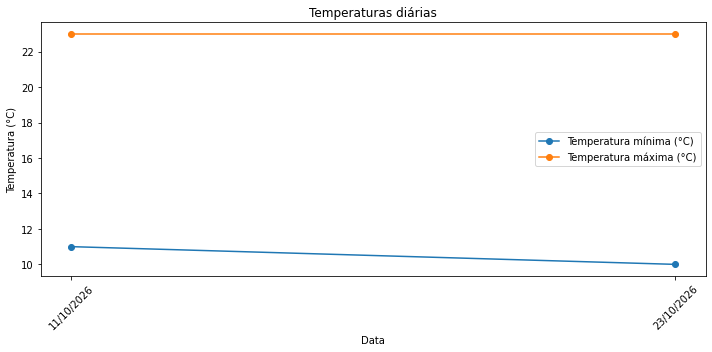

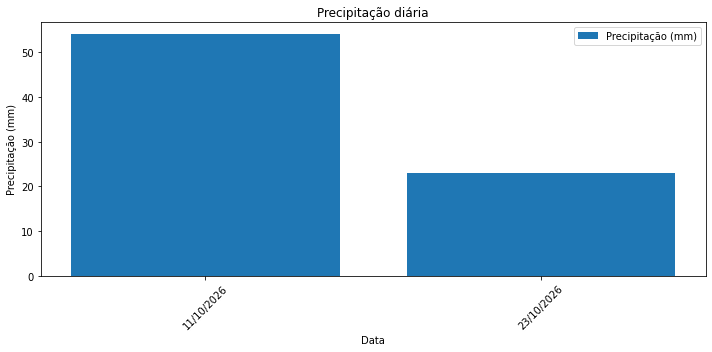


Menu de Operações:
1: Criar Tabela Meteorológica
2: Inserir Dados Meteorológicos
3: Listar Dados Meteorológicos
4: Calcular Temperatura Média
5: Calcular Temperatura Mínima
6: Calcular Amplitude Térmica
7: Calcular Máxima Precipitação
8: Listar Dias Chuvosos
9: Calcular Maior Período de Calor
10: Mostrar Gráficos de Temperatura e Precipitação
11: Guardar Tabela em Ficheiro
12: Carregar Tabela de Ficheiro
0: Sair
A sair da aplicação...


In [2]:

# Modelo: tabMeteo = [(data, tempMin, tempMax, precipitacao)]
# data = (ano, mes, dia)

from datetime import date
import os
import matplotlib.pyplot as plt

def medias(tabMeteo):
    res = []
    for registo in tabMeteo:
        data, tmin, tmax, prec = registo
        media = (tmin + tmax) / 2
        res.append((data, media))
    return res


def guardaTabMeteo(t, fnome):
    with open(fnome, "w", encoding="utf-8") as f:
        for registo in t:
            data, tmin, tmax, prec = registo
            ano, mes, dia = data
            f.write(f"{ano};{mes};{dia};{tmin};{tmax};{prec}\n")


def carregaTabMeteo(fnome):
    res = []
    with open(fnome, "r", encoding="utf-8") as f:
        for linha in f:
            campos = linha.strip().split(";")
            if len(campos) == 6:
                data = (int(campos[0]), int(campos[1]), int(campos[2]))
                registo = (data, float(campos[3]), float(campos[4]), float(campos[5]))
                res.append(registo)
    return res


def minMin(tabMeteo):
    tmin = None
    for registo in tabMeteo:
        if tmin is None or registo[1] < tmin:
            tmin = registo[1]
    return tmin


def amplTerm(tabMeteo):
    res = []
    for registo in tabMeteo:
        res.append((registo[0], registo[2] - registo[1]))
    return res


def maxChuva(tabMeteo):
    res = None
    for registo in tabMeteo:
        if res is None or registo[3] > res[1]:
            res = (registo[0], registo[3])
    return res


def diasChuvosos(tabMeteo, p):
    res = []
    for registo in tabMeteo:
        if registo[3] > p:
            res.append((registo[0], registo[3]))
    return res


def maxPeriodoCalor(tabMeteo, p):
    atual = 0
    maior = 0
    data_anterior = None
    registos_ordenados = sorted(tabMeteo)

    for registo in registos_ordenados:
        ano, mes, dia = registo[0]
        data_atual = date(ano, mes, dia)

        if registo[3] < p:
            if data_anterior is not None and (data_atual - data_anterior).days == 1 and atual > 0:
                atual = atual + 1
            else:
                atual = 1
            if atual > maior:
                maior = atual
        else:
            atual = 0

        data_anterior = data_atual
    return maior


def grafTabMeteo(t):
    if len(t) == 0:
        print("Não existem registos para representar.")
    else:
        datas = []
        minimas = []
        maximas = []
        precipitacoes = []

        for registo in sorted(t):
            ano, mes, dia = registo[0]
            datas.append(f"{dia:02d}/{mes:02d}/{ano}")
            minimas.append(registo[1])
            maximas.append(registo[2])
            precipitacoes.append(registo[3])

        plt.figure(figsize=(10, 5))
        plt.plot(datas, minimas, label="Temperatura mínima (°C)", marker="o")
        plt.plot(datas, maximas, label="Temperatura máxima (°C)", marker="o")
        plt.xlabel("Data")
        plt.ylabel("Temperatura (°C)")
        plt.title("Temperaturas diárias")
        plt.xticks(rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(10, 5))
        plt.bar(datas, precipitacoes, label="Precipitação (mm)")
        plt.xlabel("Data")
        plt.ylabel("Precipitação (mm)")
        plt.title("Precipitação diária")
        plt.xticks(rotation=45)
        plt.legend()
        plt.tight_layout()
        plt.show()


def menu():
    tabMeteo = []
    continuar = True

    while continuar:
        print("\nMenu de Operações:")
        print("1: Criar Tabela Meteorológica")
        print("2: Inserir Dados Meteorológicos")
        print("3: Listar Dados Meteorológicos")
        print("4: Calcular Temperatura Média")
        print("5: Calcular Temperatura Mínima")
        print("6: Calcular Amplitude Térmica")
        print("7: Calcular Máxima Precipitação")
        print("8: Listar Dias Chuvosos")
        print("9: Calcular Maior Período de Calor")
        print("10: Mostrar Gráficos de Temperatura e Precipitação")
        print("11: Guardar Tabela em Ficheiro")
        print("12: Carregar Tabela de Ficheiro")
        print("0: Sair")

        opcao = input("Escolha uma opção: ")

        if opcao == "1":
            tabMeteo = []
            print("Tabela meteorológica criada.")

        elif opcao == "2":
            partes_data = input("Insira a data (ano/mes/dia): ").split("/")
            ano = int(partes_data[0])
            mes = int(partes_data[1])
            dia = int(partes_data[2])
            data = (ano, mes, dia)
            temp_min = float(input("Insira a temperatura mínima: "))
            temp_max = float(input("Insira a temperatura máxima: "))
            precipitacao = float(input("Insira a precipitação: "))
            tabMeteo.append((data, temp_min, temp_max, precipitacao))
            print("Dados inseridos com sucesso.")

        elif opcao == "3":
            if tabMeteo:
                for reg in tabMeteo:
                    print(reg)
            else:
                print("Nenhum dado meteorológico registado.")

        elif opcao == "4":
            print("Temperaturas médias:", medias(tabMeteo))

        elif opcao == "5":
            if tabMeteo:
                print("Temperatura mínima mais baixa:", minMin(tabMeteo))
            else:
                print("Não existem registos.")

        elif opcao == "6":
            print("Amplitude térmica:", amplTerm(tabMeteo))

        elif opcao == "7":
            if tabMeteo:
                print("Máxima precipitação:", maxChuva(tabMeteo))
            else:
                print("Não existem registos.")

        elif opcao == "8":
            p = float(input("Valor de precipitação a ultrapassar: "))
            print("Dias chuvosos:", diasChuvosos(tabMeteo, p))

        elif opcao == "9":
            p = float(input("Limite de precipitação: "))
            print("Maior período:", maxPeriodoCalor(tabMeteo, p))

        elif opcao == "10":
            grafTabMeteo(tabMeteo)

        elif opcao == "11":
            fnome = input("Nome do ficheiro para guardar: ")
            guardaTabMeteo(tabMeteo, fnome)
            print("Tabela guardada.")

        elif opcao == "12":
            fnome = input("Nome do ficheiro para carregar: ")
            if os.path.isfile(fnome):
                tabMeteo = carregaTabMeteo(fnome)
                print("Tabela carregada.")
            else:
                print("O ficheiro não existe.")

        elif opcao == "0":
            print("A sair da aplicação...")
            continuar = False

        else:
            print("Opção inválida! Tente novamente.")


if __name__ == "__main__":
    menu()
